<a href="https://colab.research.google.com/github/sonalisankar/E-Commerce_Sales_Customer_Analytics/blob/main/E_Commerce_Sales_Customer_Analytics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:

customers = pd.read_csv("customers.csv")
orders = pd.read_csv("orders.csv")
order_items = pd.read_csv("order_items.csv")
products = pd.read_csv("products.csv")
sales = pd.read_csv("sales_cleaned.csv")

print("All five datasets loaded successfully!")

All five datasets loaded successfully!


In [ ]:
datasets = {
    "Customers": customers,
    "Orders": orders,
    "Order Items": order_items,
    "Products": products,
    "Cleaned Sales": sales
}

for name, df in datasets.items():
    print(f"\n{'=' * 50}")
    print(f"DATASET: {name}")
    print(f"{'=' * 50}")

    print("Rows and columns:", df.shape)

    print("\nColumn names:")
    print(df.columns.tolist())

    print("\nFirst five rows:")
    display(df.head())


DATASET: Customers
Rows and columns: (300, 3)

Column names:
['customer_id', 'country', 'signup_date']

First five rows:


,customer_id,country,signup_date
0,1,Spain,2023-05-15
1,2,Italy,2023-02-10
2,3,Spain,2023-10-23
3,4,France,2023-01-03
4,5,Italy,2024-02-05



DATASET: Orders
Rows and columns: (1000, 4)

Column names:
['order_id', 'customer_id', 'order_date', 'status']

First five rows:


,order_id,customer_id,order_date,status
0,1,103,2024-10-31,Completed
1,2,271,2024-10-12,Completed
2,3,107,2024-05-23,Completed
3,4,72,2024-01-19,Completed
4,5,189,2024-01-18,Completed



DATASET: Order Items
Rows and columns: (2000, 4)

Column names:
['order_id', 'product_id', 'quantity', 'price']

First five rows:


,order_id,product_id,quantity,price
0,508,48,3,108
1,290,18,2,93
2,295,16,2,27
3,451,39,2,54
4,904,4,4,117



DATASET: Products
Rows and columns: (50, 3)

Column names:
['product_id', 'product_name', 'category']

First five rows:


,product_id,product_name,category
0,1,Product_1,Body
1,2,Product_2,Skin
2,3,Product_3,Hair
3,4,Product_4,Body
4,5,Product_5,Skin



DATASET: Cleaned Sales
Rows and columns: (1625, 10)

Column names:
['order_id', 'product_id', 'quantity', 'price', 'Revenue', 'customer_id', 'order_date', 'status', 'year', 'month']

First five rows:


,order_id,product_id,quantity,price,Revenue,customer_id,order_date,status,year,month
0,290,18,2,93,186,256,2024-08-26,Completed,2024,8
1,290,20,4,102,408,256,2024-08-26,Completed,2024,8
2,290,19,1,25,25,256,2024-08-26,Completed,2024,8
3,295,16,2,27,54,54,2024-06-25,Completed,2024,6
4,295,13,3,48,144,54,2024-06-25,Completed,2024,6


In [ ]:
for name, df in datasets.items():
    print(f"\n{'=' * 50}")
    print(f"DATA QUALITY: {name}")
    print(f"{'=' * 50}")

    print("\nMissing values:")
    print(df.isnull().sum())

    print("\nDuplicate rows:")
    print(df.duplicated().sum())

    print("\nData types:")
    print(df.dtypes)


DATA QUALITY: Customers

Missing values:
customer_id    0
country        0
signup_date    0
dtype: int64

Duplicate rows:
0

Data types:
customer_id     int64
country        object
signup_date    object
dtype: object

DATA QUALITY: Orders

Missing values:
order_id       0
customer_id    0
order_date     0
status         0
dtype: int64

Duplicate rows:
0

Data types:
order_id        int64
customer_id     int64
order_date     object
status         object
dtype: object

DATA QUALITY: Order Items

Missing values:
order_id      0
product_id    0
quantity      0
price         0
dtype: int64

Duplicate rows:
0

Data types:
order_id      int64
product_id    int64
quantity      int64
price         int64
dtype: object

DATA QUALITY: Products

Missing values:
product_id      0
product_name    0
category        0
dtype: int64

Duplicate rows:
0

Data types:
product_id       int64
product_name    object
category        object
dtype: object

DATA QUALITY: Cleaned Sales

Missing values:
order_id    

In [ ]:
# Inspect the cleaned sales columns
print("Columns:", sales.columns.tolist())

display(sales.head())

Columns: ['order_id', 'product_id', 'quantity', 'price', 'Revenue', 'customer_id', 'order_date', 'status', 'year', 'month']


,order_id,product_id,quantity,price,Revenue,customer_id,order_date,status,year,month
0,290,18,2,93,186,256,2024-08-26,Completed,2024,8
1,290,20,4,102,408,256,2024-08-26,Completed,2024,8
2,290,19,1,25,25,256,2024-08-26,Completed,2024,8
3,295,16,2,27,54,54,2024-06-25,Completed,2024,6
4,295,13,3,48,144,54,2024-06-25,Completed,2024,6


In [ ]:

import pandas as pd
import os

# STEP 1: Check whether your CSV files are available
print("Checking uploaded files...")

print(os.listdir())

# STEP 2: Load the five datasets
customers = pd.read_csv("customers.csv")
orders = pd.read_csv("orders.csv")
order_items = pd.read_csv("order_items.csv")
products = pd.read_csv("products.csv")
sales = pd.read_csv("sales_cleaned.csv")

print("\nAll five datasets loaded successfully!")

# STEP 3: Combine the datasets
analysis_df = order_items.merge(
    orders,
    on="order_id",
    how="left",
    validate="many_to_one"
)

analysis_df = analysis_df.merge(
    customers,
    on="customer_id",
    how="left",
    validate="many_to_one"
)

analysis_df = analysis_df.merge(
    products,
    on="product_id",
    how="left",
    validate="many_to_one"
)

# STEP 4: Calculate revenue
analysis_df["revenue"] = (
    analysis_df["quantity"] * analysis_df["price"]
)

# STEP 5: Format dates
analysis_df["order_date"] = pd.to_datetime(
    analysis_df["order_date"],
    errors="coerce"
)

analysis_df["signup_date"] = pd.to_datetime(
    analysis_df["signup_date"],
    errors="coerce"
)

# STEP 6: Create a month field for trend analysis
analysis_df["year_month"] = (
    analysis_df["order_date"].dt.to_period("M").astype(str)
)

print("\nAnalytical dataset created!")
print("Number of rows:", len(analysis_df))
print("Number of columns:", len(analysis_df.columns))

display(analysis_df.head())

# STEP 7: Filter completed orders
completed_sales = analysis_df[
    analysis_df["status"].astype(str).str.strip().str.lower()
    == "completed"
].copy()

# STEP 8: Calculate KPIs
total_revenue = completed_sales["revenue"].sum()
total_orders = completed_sales["order_id"].nunique()
unique_customers = completed_sales["customer_id"].nunique()
units_sold = completed_sales["quantity"].sum()

average_order_value = (
    total_revenue / total_orders
    if total_orders > 0 else 0
)

# STEP 9: Calculate repeat customer rate
orders_per_customer = (
    completed_sales
    .dropna(subset=["customer_id"])
    .groupby("customer_id")["order_id"]
    .nunique()
)

repeat_customer_rate = (
    (orders_per_customer >= 2).mean() * 100
    if len(orders_per_customer) > 0 else 0
)

# STEP 10: Display KPI table
kpis = pd.DataFrame({
    "KPI": [
        "Total Revenue",
        "Total Orders",
        "Unique Customers",
        "Units Sold",
        "Average Order Value",
        "Repeat Customer Rate (%)"
    ],
    "Value": [
        round(total_revenue, 2),
        total_orders,
        unique_customers,
        units_sold,
        round(average_order_value, 2),
        round(repeat_customer_rate, 2)
    ]
})

print("\n========== BUSINESS KPI RESULTS ==========")
display(kpis)

# STEP 11: Revenue by product category
print("\n========== REVENUE BY CATEGORY ==========")

category_revenue = (
    completed_sales.groupby("category")["revenue"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

display(category_revenue)

# STEP 12: Monthly revenue
print("\n========== MONTHLY REVENUE ==========")

monthly_revenue = (
    completed_sales.groupby("year_month")["revenue"]
    .sum()
    .reset_index()
    .rename(columns={
        "year_month": "Month",
        "revenue": "Revenue"
    })
)

display(monthly_revenue)

# STEP 13: Revenue by country
print("\n========== REVENUE BY COUNTRY ==========")

country_revenue = (
    completed_sales.groupby("country")["revenue"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

display(country_revenue)

# STEP 14: Order status counts
print("\n========== ORDER STATUS COUNTS ==========")
display(orders["status"].value_counts().rename_axis("Status").reset_index(name="Count"))

Checking uploaded files...
['.config', 'customers.csv', 'products.csv', 'order_items.csv', 'sales_cleaned.csv', 'orders.csv', 'sample_data']

All five datasets loaded successfully!

Analytical dataset created!
Number of rows: 2000
Number of columns: 13


,order_id,product_id,quantity,price,customer_id,order_date,status,country,signup_date,product_name,category,revenue,year_month
0,508,48,3,108,170,2024-10-14,Cancelled,Morocco,2023-09-07,Product_48,Hair,324,2024-10
1,290,18,2,93,256,2024-08-26,Completed,Germany,2023-06-03,Product_18,Makeup,186,2024-08
2,295,16,2,27,54,2024-06-25,Completed,Morocco,2023-06-12,Product_16,Makeup,54,2024-06
3,451,39,2,54,152,2024-04-22,Completed,Morocco,2023-09-15,Product_39,Hair,108,2024-04
4,904,4,4,117,159,2024-10-08,Completed,France,2023-02-07,Product_4,Body,468,2024-10



========== BUSINESS KPI RESULTS ==========


,KPI,Value
0,Total Revenue,311111.00
1,Total Orders,695.00
2,Unique Customers,267.00
3,Units Sold,4848.00
4,Average Order Value,447.64
5,Repeat Customer Rate (%),73.41



========== REVENUE BY CATEGORY ==========


...

,Month,Revenue
0,2024-01,30948
1,2024-02,23299
2,2024-03,27014
3,2024-04,27839
4,2024-05,22961
5,2024-06,22819
6,2024-07,24119
7,2024-08,27371
8,2024-09,23332
9,2024-10,30860



========== REVENUE BY COUNTRY ==========


,country,revenue
0,Italy,70719
1,Spain,69897
2,Morocco,65164
3,France,55976
4,Germany,49355



========== ORDER STATUS COUNTS ==========


,Status,Count
0,Completed,805
1,Cancelled,103
2,Returned,92


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
product_revenue = (
completed_sales.groupby("product_name")["revenue"]
.sum()
.sort_values(ascending=False)
.head(10)
.reset_index()
)
print("TOP 10 PRODUCTS BY REVENUE")
display(product_revenue)

TOP 10 PRODUCTS BY REVENUE


,product_name,revenue
0,Product_16,9732
1,Product_45,9644
2,Product_25,9527
3,Product_23,9426
4,Product_6,8661
5,Product_47,8119
6,Product_13,8065
7,Product_4,7788
8,Product_32,7735
9,Product_14,7474


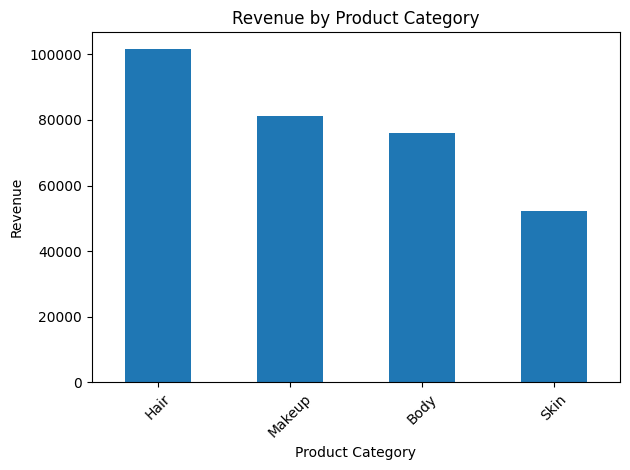

In [ ]:
category_revenue = (
completed_sales.groupby("category")["revenue"]
.sum()
.sort_values(ascending=False)
)

category_revenue.plot(kind="bar")
plt.title("Revenue by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

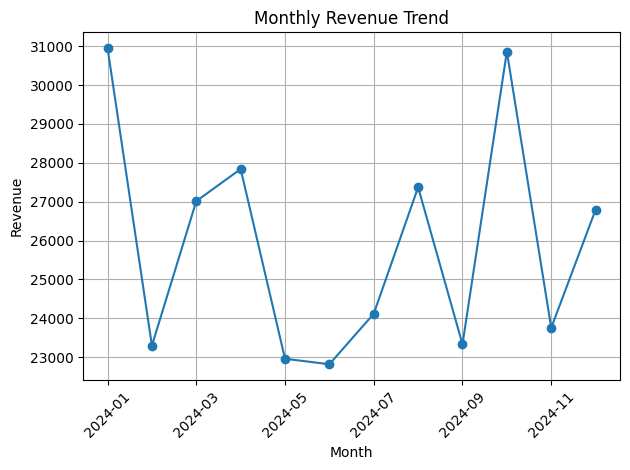

In [ ]:
monthly_revenue = (
completed_sales.groupby("year_month")["revenue"]
.sum()
.sort_index()
)

monthly_revenue.plot(kind="line", marker="o")
plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

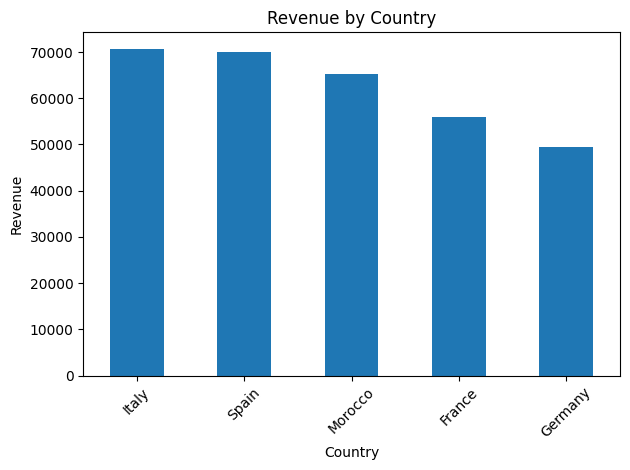

In [ ]:
country_revenue = (
completed_sales.groupby("country")["revenue"]
.sum()
.sort_values(ascending=False)
)

country_revenue.plot(kind="bar")
plt.title("Revenue by Country")
plt.xlabel("Country")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
customer_revenue = (
completed_sales.groupby("customer_id")["revenue"]
.sum()
.sort_values(ascending=False)
.head(10)
.reset_index()
)

print("TOP 10 CUSTOMERS BY REVENUE")
display(customer_revenue)

TOP 10 CUSTOMERS BY REVENUE


,customer_id,revenue
0,13,5048
1,39,4564
2,152,4309
3,144,3420
4,76,3330
5,113,2960
6,126,2960
7,130,2949
8,277,2939
9,231,2807


In [ ]:
print("SUMMARY STATISTICS")
display(
completed_sales[["quantity", "price", "revenue"]].describe()
)

SUMMARY STATISTICS


,quantity,price,revenue
count,1625.000000,1625.000000,1625.000000
mean,2.983385,64.408615,191.452923
std,1.401651,31.056883,134.584108
min,1.000000,10.000000,10.000000
25%,2.000000,37.000000,84.000000
50%,3.000000,66.000000,160.000000
75%,4.000000,90.000000,276.000000
max,5.000000,119.000000,595.000000


In [ ]:
# Export the complete joined dataset
analysis_df.to_csv("sales_analysis_ready.csv", index=False)

# Export completed sales separately
completed_sales.to_csv("completed_sales.csv", index=False)

print("Files exported successfully!")
print("Complete dataset:", analysis_df.shape)
print("Completed sales dataset:", completed_sales.shape)

Files exported successfully!
Complete dataset: (2000, 13)
Completed sales dataset: (1625, 13)


In [18]:
from google.colab import files

files.download("sales_analysis_ready.csv")
files.download("completed_sales.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>